# CSCI 3003 - Data Visualization

## Data Visualization Challenge 1: Palmer Penguins

**Name:** STEVE TATSIGUIA  
**Date:** 2026-09-15  
**Version:** Student notebook

> Add your name and date before submitting.


## Purpose

This challenge asks you to apply the data-inspection, transformation, summarization, reshaping, visualization, and interpretation skills from Labs 1-3 to a new dataset. Unlike a guided lab, the challenge gives you one broad investigation prompt. You must decide which variables and operations best support your question.

Your work should form one coherent analysis rather than a collection of unrelated commands.


## I. Meet the dataset

The simplified Palmer Penguins dataset contains measurements for 344 penguins observed on islands in the Palmer Archipelago, Antarctica. One row represents one observed penguin.

| Column | Meaning |
|---|---|
| `species` | Penguin species: Adelie, Chinstrap, or Gentoo |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Recorded sex |
| `year` | Observation year |

Some values are missing. Treat missingness as part of the dataset rather than as an error to hide.

**Source:** Horst, Hill, and Gorman, *palmerpenguins: Palmer Archipelago (Antarctica) penguin data* (2020), based on data collected by Kristen Gorman and the Palmer Station Long Term Ecological Research Program. Data are available under a CC0 license. [Dataset documentation](https://github.com/allisonhorst/palmerpenguins) (accessed September 7, 2026).


## II. Setup

Read in the `penguins.csv` dataset. The configured Jupyter working directory should be `01-labs/`. 


In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [18]:
penguin_file = Path("penguins.csv")
penguin_file.exists()

True

In [19]:
penguins = pd.read_csv(penguin_file)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [20]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## III. Challenge

What meaningful differences or relationships can you identify among the Palmer penguins? Profile the dataset, pose one or more focused investigation question, and build a reproducible analysis that answers it. Your choices should be driven by your question and the meanings of the variables.

Your submitted investigation must provide evidence that you can:

- inspect the rows, dimensions, column names, data types, and missing values;
- select the variables relevant to your investigation;
- create and interpret a one-variable frequency table with `.value_counts()`;
- create and interpret a two-variable frequency table with `pd.crosstab()`;
- filter your data and sort the retained observations purposefully;
- address missing values deliberately and explain your choice;
- where helpful, create derived column(s) with `.assign()`;
- use a readable, parenthesized method chain;
- use `.groupby()` and named `.agg()` calculations;
- create a relevant pivot table and if needed, convert it to tidy form with `.melt()`;
- create appropriate charts to anwer your questions
- use specific results to answer your question and identify one limitation.

You may add Markdown and code cells as needed. Do not use a method merely to check off a requirement: explain how each table, transformation, or plot contributes to the investigation.

**Your investigation question(s):**  How do body mass and flipper length differ between the three penguin species, and how are the species distributed across the islands?




### A. Profile and plan

Establish what the dataset contains, assess missingness, and explain why your selected variables can answer your investigation question.


In [21]:
# Look at the size and structure of the dataset
print("Shape:", penguins.shape)
print("\nColumns:")
print(penguins.columns)

print("\nMissing values:")
print(penguins.isna().sum())

Shape: (344, 8)

Columns:
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

Missing values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


**Answer:** The dataset has 344 penguins and 8 columns. I want to compare species, body mass, flipper length, and island because these variables can help show differences between penguin species and where they are found. There are also some missing values, especially in sex and a few of the measurement columns.




### B. Explore qualitative variables

Use one- and two-variable counts to learn about categories relevant to your investigation. Include a labeled bar chart that supports a useful comparison.


In [22]:
species_counts = penguins["species"].value_counts()
species_counts

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [23]:
species_island = pd.crosstab(
    penguins["island"],
    penguins["species"]
)

species_island

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


**Answer:** Adelie is the most common species with 152 penguins. Gentoo has 124 and Chinstrap has 68. The two-way table also shows that Gentoo penguins are only on Biscoe Island and Chinstrap penguins are only on Dream Island. Adelie penguins are found on all three islands




### C. Transform and summarize

Filter, sort, handle missing values, create a derived column, and construct a grouped summary. Organize the central workflow as a readable method chain.


In [24]:
analysis_penguins = (
    penguins
    .dropna(subset=["body_mass_g", "flipper_length_mm"])
    .assign(
        body_mass_kg=lambda x: x["body_mass_g"] / 1000
    )
)

analysis_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.75
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.80
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,3.25
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.45
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007,3.65


In [25]:
large_penguins = (
    analysis_penguins
    .loc[analysis_penguins["body_mass_g"] >= 5000]
    .sort_values("body_mass_g", ascending=False)
)

large_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,body_mass_kg
169,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,male,2007,6.30
185,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,male,2007,6.05
269,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,male,2009,6.00
229,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,male,2008,6.00
231,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,male,2008,5.95


In [26]:
species_summary = (
    analysis_penguins
    .groupby("species")
    .agg(
        penguin_count=("species", "size"),
        avg_body_mass_g=("body_mass_g", "mean"),
        avg_flipper_length_mm=("flipper_length_mm", "mean")
    )
    .round(1)
)

species_summary

,penguin_count,avg_body_mass_g,avg_flipper_length_mm
species,,,
Adelie,151,3700.7,190.0
Chinstrap,68,3733.1,195.8
Gentoo,123,5076.0,217.2


**Answer:** Gentoo penguins are much heavier and have longer flippers than the other species. Their average body mass is about 5076 grams and their average flipper length is about 217 mm. Adelie and Chinstrap penguins are closer in body mass, around 3700 grams.




### D. Reshape and visualize

Create a pivot table relevant to your question, reshape it to tidy form, and create a labeled scatterplot that reveals a useful numerical relationship. You may include additional plots when they materially strengthen the analysis.


In [27]:
measurement_table = penguins.pivot_table(
    index="species",
    values=["body_mass_g", "flipper_length_mm"],
    aggfunc="mean"
).round(1)

measurement_table

,body_mass_g,flipper_length_mm
species,,
Adelie,3700.7,190.0
Chinstrap,3733.1,195.8
Gentoo,5076.0,217.2


In [28]:
measurement_tidy = (
    measurement_table
    .reset_index()
    .melt(
        id_vars="species",
        var_name="measurement",
        value_name="average"
    )
)

measurement_tidy

,species,measurement,average
0,Adelie,body_mass_g,3700.7
1,Chinstrap,body_mass_g,3733.1
2,Gentoo,body_mass_g,5076.0
3,Adelie,flipper_length_mm,190.0
4,Chinstrap,flipper_length_mm,195.8
5,Gentoo,flipper_length_mm,217.2


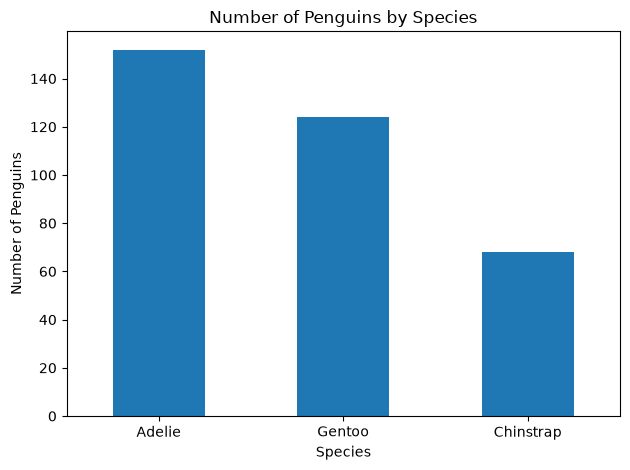

In [29]:
ax = species_counts.plot.bar()

ax.set_title("Number of Penguins by Species")
ax.set_xlabel("Species")
ax.set_ylabel("Number of Penguins")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

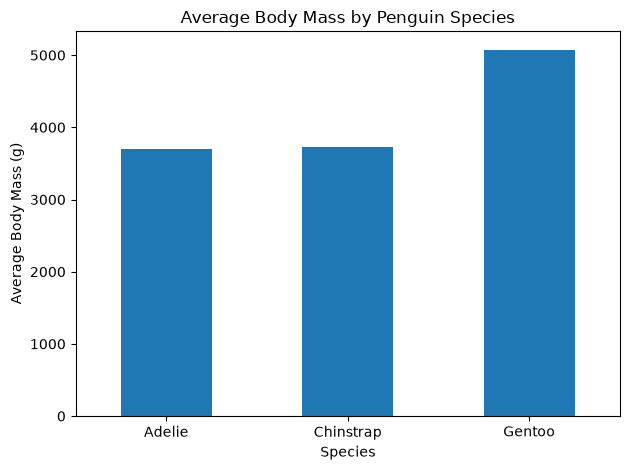

In [30]:
avg_mass = (
    analysis_penguins
    .groupby("species")["body_mass_g"]
    .mean()
)

ax = avg_mass.plot.bar()

ax.set_title("Average Body Mass by Penguin Species")
ax.set_xlabel("Species")
ax.set_ylabel("Average Body Mass (g)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

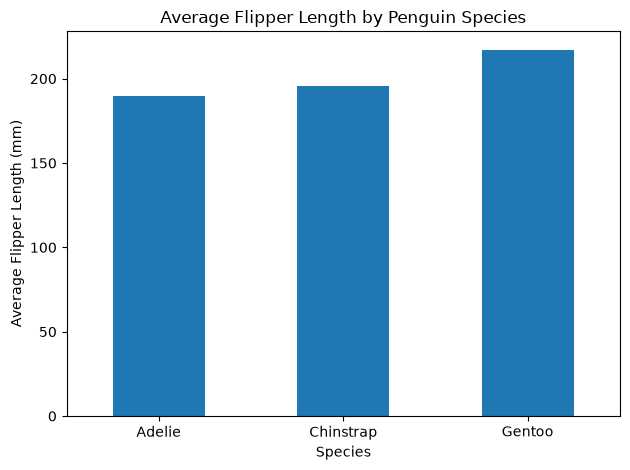

In [31]:
avg_flipper = (
    analysis_penguins
    .groupby("species")["flipper_length_mm"]
    .mean()
)

ax = avg_flipper.plot.bar()

ax.set_title("Average Flipper Length by Penguin Species")
ax.set_xlabel("Species")
ax.set_ylabel("Average Flipper Length (mm)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### E. Conclusion

Answer your investigation question in 4-6 sentences. Cite specific values or visible patterns, explain what one mark in each plot represents, and identify one important limitation of your analysis.

**Answer:** My investigation shows that there are clear differences between the penguin species. Gentoo penguins are the biggest overall, with an average body mass of about 5076 grams and an average flipper length of about 217 mm. Adelie and Chinstrap penguins are lighter and have shorter flippers. Adelie is also the most common species in the dataset with 152 penguins. The species are not evenly spread across the islands because Gentoo penguins are only found on Biscoe Island and Chinstrap penguins are only found on Dream Island. One limitation is that some rows have missing measurements, so not every penguin could be used in every calculation.




## IV. Submission check

Before exporting:

- Add your name and date and state a focused investigation question.
- Confirm that every required skill appears and supports the investigation.
- Label every plot with a descriptive title and readable axis labels.
- Restart the kernel and run all cells from top to bottom.
- Resolve all errors and remove accidental or excessively large output.
- Export to HTML and inspect the exported file.
